# Application Scorecard built on the PD Model

`pd_model_nn.ipynb` produces a **probability of default (PD)** for every loan. Credit policy, underwriters and collections do not work with raw probabilities — they work with a **score** (e.g. 540), a **risk grade** (A–H) and a **cut-off** (approve above 560). This notebook shows how the scorecard is built on top of the champion PD model.

```
 PD model (XGBoost champion)
      │  raw PD — inflated by the 1:3 class weight
      ▼
 1. Calibrate        → true PD that matches the actual default rate
      ▼
 2. PD → odds        → good:bad odds = (1 − PD) / PD
      ▼
 3. Odds → points    → Score = Offset + Factor × ln(odds)   (PDO scaling)
      ▼
 4. Risk grades      → score bands, each band ≈ double the odds of the one below
      ▼
 5. Cut-off strategy → approve / refer / decline, approval rate vs bad rate
      ▼
 6. Points breakdown → base points + points per characteristic = score, and reason codes
```

**Traditional scorecard vs a scorecard on an ML model**

| | Traditional scorecard | This notebook |
|---|---|---|
| Model | Logistic regression on WoE-binned variables | XGBoost champion |
| Points per characteristic | Coefficient × WoE × Factor | SHAP value × Factor |
| Score scaling (PDO) | Same formula | Same formula |
| Grades, cut-offs, reason codes | Same | Same |

Steps 2–5 are identical whatever model sits underneath. Only step 6 changes: SHAP takes the place of the WoE points table.

## 0. Rebuild the champion PD model

Same data, look-ahead removal, feature engineering, split and XGBoost settings as `pd_model_nn.ipynb`, condensed. Only the columns the model needs are loaded. The neural-network challenger is not rebuilt: XGBoost is the champion, so the scorecard sits on top of it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Variables kept for the first round of review (same list as pd_model_nn.ipynb)
cons_var=['acc_open_past_24mths','addr_state','all_util','annual_inc','annual_inc_joint','application_type','chargeoff_within_12_mths',
          'collections_12_mths_ex_med','delinq_2yrs','dti','dti_joint','emp_length','emp_title','fico_range_high','fico_range_low',
          'home_ownership','id','il_util','inq_last_12m','loan_amnt','member_id','mort_acc',
          'num_accts_ever_120_pd','num_bc_tl','num_il_tl','num_op_rev_tl','num_rev_accts','num_tl_90g_dpd_24m','num_tl_op_past_12m','open_il_12m',
          'open_il_24m','open_rv_12m','open_rv_24m','percent_bc_gt_75','pub_rec','pub_rec_bankruptcies','purpose','revol_bal','revol_util',
          'sub_grade','tax_liens','title','tot_coll_amt','tot_hi_cred_lim','total_bal_ex_mort','total_bc_limit','total_cu_tl',
          'total_il_high_credit_limit','total_rev_hi_lim','verification_status','zip_code','revol_bal_joint','sec_app_fico_range_low',
          'sec_app_fico_range_high','sec_app_inq_last_6mths','sec_app_mort_acc','sec_app_open_acc','sec_app_open_act_il','sec_app_num_rev_accts',
          'sec_app_chargeoff_within_12_mths','sec_app_collections_12_mths_ex_med','sec_app_mths_since_last_major_derog']

df1 = pd.read_parquet("data/lendingclubfull.parquet", columns=cons_var + ['loan_status'])

# Target: 0 = Fully Paid, 1 = Charged Off or Late 31-120 days; other statuses have no outcome yet (NaN)
df1['Y'] = df1['loan_status'].map({'Fully Paid': 0, 'Charged Off': 1, 'Late (31-120 days)': 1})
df1 = df1.drop(columns='loan_status')
df1.shape

Out[1]: (2260701, 63)


(2260701, 63)

In [2]:
# Feature engineering — identical to pd_model_nn.ipynb
df1['total_inc']= df1['annual_inc_joint'].fillna(df1['annual_inc'])
df1['tot_chargeoff_within_12_mths'] = (df1['chargeoff_within_12_mths'] + df1['sec_app_chargeoff_within_12_mths'].fillna(0))
df1['tot_dti'] = df1['dti_joint'].fillna(df1['dti'])
df1['fico_avg'] = (df1['fico_range_low'] + df1['fico_range_high'])/2
df1['tot_limit']= df1['tot_hi_cred_lim']
df1['tot_unsec_limit']= df1['total_il_high_credit_limit'] + df1['total_rev_hi_lim']
df1['tot_sec_limit'] = df1['tot_hi_cred_lim'] - df1['tot_unsec_limit']
df1['tot_sec_limit'] = np.where(df1['tot_sec_limit'] < 0, 0, df1['tot_sec_limit'])
df1['tot_acct']= df1['num_il_tl'] + df1['num_rev_accts'].fillna(0) + df1['mort_acc']
df1['tot_unsec_acct'] = df1['num_il_tl'] + df1['num_rev_accts'].fillna(0)
df1['tot_sec_acct']= df1['mort_acc']
df1['tot_unsec_util'] = df1['total_bal_ex_mort']/ df1['tot_unsec_limit']*100
df1['tot_unsec_util']= df1['tot_unsec_util'].fillna(0)
df1['tot_unsec_bal'] = df1['total_bal_ex_mort']
df1['Num_30DPD_2yrs'] = df1['delinq_2yrs']
df1['Num_90DPD_2yrs'] = df1['num_tl_90g_dpd_24m']
df1['num_acc_op_past_12m']= df1['num_tl_op_past_12m']
df1['num_acc_op_past_24mths'] = df1['acc_open_past_24mths']
df1['emp_length_num'] = df1['emp_length'].map(
    {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5,
     '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10})
df1['zip_code'] = df1['zip_code'].map(df1['zip_code'].value_counts(normalize=True))

df1=df1.drop(['addr_state','application_type', 'emp_title','id','member_id','tax_liens','title','sec_app_mort_acc','sec_app_open_acc',
          'sec_app_open_act_il','sec_app_num_rev_accts','sec_app_collections_12_mths_ex_med','sec_app_mths_since_last_major_derog',
          'sec_app_inq_last_6mths','num_bc_tl','num_op_rev_tl','open_il_12m','open_il_24m','open_rv_12m','open_rv_24m','pub_rec',
          'revol_bal','total_bc_limit','total_cu_tl','revol_bal_joint','sec_app_fico_range_low','sec_app_fico_range_high',
          'chargeoff_within_12_mths','sec_app_chargeoff_within_12_mths','fico_range_high','fico_range_low','annual_inc',
          'annual_inc_joint','dti','dti_joint','mort_acc','num_il_tl','num_rev_accts', 'total_rev_hi_lim','total_il_high_credit_limit',
          'tot_hi_cred_lim','il_util','revol_util','all_util','total_bal_ex_mort','delinq_2yrs','num_tl_90g_dpd_24m', 'percent_bc_gt_75',
            'emp_length','num_tl_op_past_12m','acc_open_past_24mths', 'sub_grade'], axis= 1)

# Loans with a final outcome and credit-limit data
df1 = df1.loc[df1['Y'].notnull()]
df1 = df1.dropna(subset=['tot_limit'])
df1.shape

Out[2]: (1299250, 28)


(1299250, 28)

In [3]:
# Split and preprocessing — identical to pd_model_nn.ipynb (same random_state, so the same split)
df1['inq_last_12m_missing'] = df1['inq_last_12m'].isna().astype(int)
df1['emp_length_missing'] = df1['emp_length_num'].isna().astype(int)
df1['tot_unsec_util_gt_100'] = (df1['tot_unsec_util'] > 100).astype(int)

x= df1.drop('Y', axis= 1)
y= df1['Y']
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size= 0.2, random_state= 42, stratify= y)

emp_length_median = x_train['emp_length_num'].median()
x_train['emp_length_num']= x_train['emp_length_num'].fillna(emp_length_median)
x_test['emp_length_num']= x_test['emp_length_num'].fillna(emp_length_median)

inq_last_12m_median = x_train['inq_last_12m'].median()
x_train['inq_last_12m']= x_train['inq_last_12m'].fillna(inq_last_12m_median)
x_test['inq_last_12m']= x_test['inq_last_12m'].fillna(inq_last_12m_median)

x_train['tot_unsec_util'] = x_train['tot_unsec_util'].clip(upper=100)
x_test['tot_unsec_util'] = x_test['tot_unsec_util'].clip(upper=100)

# NEW for the scorecard: keep the test set in original units (before log / scaling),
# so the points breakdown can show "FICO 680" rather than "FICO -0.42 standard deviations".
x_test_raw = x_test.copy()

log_scale_cols= ['loan_amnt','tot_coll_amt','total_inc','tot_limit','tot_unsec_limit','tot_sec_limit','tot_unsec_bal']
for i in log_scale_cols:
    x_train[i]= np.log1p(x_train[i])
    x_test[i]= np.log1p(x_test[i])

one_hot_cols = ['home_ownership', 'purpose', 'verification_status']
x_train = pd.get_dummies(x_train, columns=one_hot_cols, drop_first=True, dtype=int)
x_test = pd.get_dummies(x_test, columns=one_hot_cols, drop_first=True, dtype=int)
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

stan_scale_cols=['collections_12_mths_ex_med', 'inq_last_12m', 'loan_amnt', 'num_accts_ever_120_pd',
       'pub_rec_bankruptcies','tot_coll_amt', 'total_inc', 'tot_chargeoff_within_12_mths', 'tot_dti', 'fico_avg',
       'tot_limit', 'tot_unsec_limit', 'tot_sec_limit', 'tot_acct', 'tot_unsec_acct', 'tot_sec_acct', 'tot_unsec_util',
       'tot_unsec_bal', 'Num_30DPD_2yrs', 'Num_90DPD_2yrs', 'num_acc_op_past_12m', 'num_acc_op_past_24mths', 'emp_length_num']
scaler = StandardScaler()
x_train[stan_scale_cols] = scaler.fit_transform(x_train[stan_scale_cols])
x_test[stan_scale_cols] = scaler.transform(x_test[stan_scale_cols])

# Features dropped after the feature-selection checks
cols_to_drop = ['purpose_home_improvement', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving',
    'pub_rec_bankruptcies', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business',
    'purpose_vacation', 'purpose_wedding', 'purpose_house', 'home_ownership_OTHER',
    'home_ownership_OWN', 'home_ownership_NONE', 'tot_unsec_util_gt_100', 'tot_coll_amt']
x_train = x_train.drop(columns=cols_to_drop, axis=1)
x_test = x_test.drop(columns=cols_to_drop, axis=1)
x_test['zip_code']= x_test['zip_code'].fillna(0)

print(f"Train: {x_train.shape}   Test: {x_test.shape}   Features: {x_train.shape[1]}")
print(f"Default rate - train {y_train.mean():.2%}, test {y_test.mean():.2%}")

Train: (1039400, 30)   Test: (259850, 30)   Features: 30
Default rate - train 21.53%, test 21.53%


In [4]:
# CHAMPION: XGBoost — same settings as pd_model_nn.ipynb
xgb_model = xgb.XGBClassifier(
    n_estimators=1000, max_depth=6, learning_rate=0.05, min_child_weight=50,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=3,          # defaults count 3x — this is why the PD needs calibrating (step 1)
    tree_method='hist', eval_metric='auc', early_stopping_rounds=50,
    random_state=42, verbosity=0)
xgb_model.fit(x_train, y_train, eval_set=[(x_test, y_test)], verbose=200)

print(f"\nChampion test AUC: {roc_auc_score(y_test, xgb_model.predict_proba(x_test)[:, 1]):.4f}")
print("pd_model_nn.ipynb reported 0.7025; a gap of ~0.001 is normal run-to-run / library-version variation.")

[0]	validation_0-auc:0.63744
[200]	validation_0-auc:0.69632
[400]	validation_0-auc:0.69924
[600]	validation_0-auc:0.70029
[800]	validation_0-auc:0.70092
[999]	validation_0-auc:0.70119

Champion test AUC: 0.7012
pd_model_nn.ipynb reported 0.7025; a gap of ~0.001 is normal run-to-run / library-version variation.


## 1. Calibrate the PD

A scorecard turns **odds** into points, so the PD going in has to be a real probability. The champion was trained with `scale_pos_weight = 3`: every default counted as three. That improves ranking but inflates the predicted PD — the model behaves as if there were three times as many defaults as there really are.

The fix is a **prior correction**. Weighting the defaults by 3 multiplies the model's bad:good odds by 3, so dividing them by 3 undoes it. On the log-odds scale it is a single shift:

$$\text{logit}(PD_{\text{true}}) = \text{logit}(PD_{\text{raw}}) - \ln 3$$

Ranking is untouched (AUC is the same), only the level moves. The check is simple: the average calibrated PD should equal the actual default rate.

In [5]:
CLASS_WEIGHT = 3
sigmoid = lambda z: 1 / (1 + np.exp(-z))

# The model's raw output in log-odds ("margin"), before the sigmoid
margin_train = xgb_model.predict(x_train, output_margin=True)
margin_test  = xgb_model.predict(x_test,  output_margin=True)

pd_raw_train, pd_raw_test = sigmoid(margin_train), sigmoid(margin_test)
pd_cal_train = sigmoid(margin_train - np.log(CLASS_WEIGHT))
pd_cal_test  = sigmoid(margin_test  - np.log(CLASS_WEIGHT))

pd.DataFrame({
    'Actual default rate': [y_train.mean(), y_test.mean()],
    'Mean raw PD (1:3 weighted)': [pd_raw_train.mean(), pd_raw_test.mean()],
    'Mean calibrated PD': [pd_cal_train.mean(), pd_cal_test.mean()],
}, index=['Train', 'Test']).style.format('{:.2%}')

Out[5]: <pandas.io.formats.style.Styler at 0x26ce525f620>


,Actual default rate,Mean raw PD (1:3 weighted),Mean calibrated PD
Train,21.53%,41.82%,21.28%
Test,21.53%,41.78%,21.24%


Calibration by decile, test set (rates in %)

        Accounts  Actual_DR  Raw_PD  Calibrated_PD
decile                                            
1          25985       5.02   13.46           4.98
2          25985       9.15   22.59           8.88
3          25985      11.78   28.57          11.78
4          25985      15.34   33.79          14.55
5          25985      17.90   38.80          17.46
6          25985      21.01   43.76          20.61
7          25985      24.75   48.90          24.20
8          25985      29.02   54.53          28.58
9          25985      35.06   61.31          34.62
10         25985      46.26   72.12          46.75


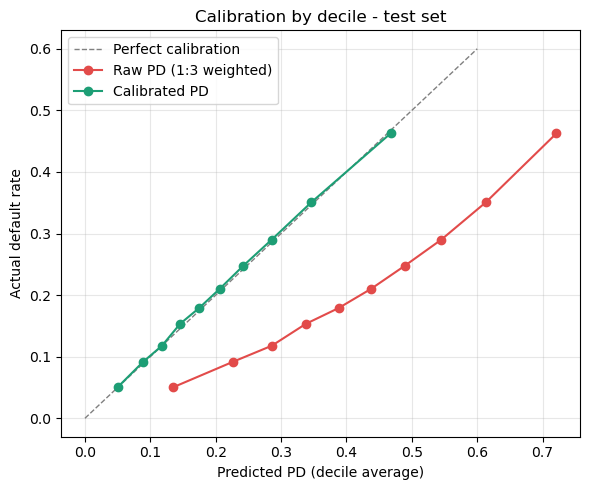

In [6]:
# Calibration by decile on the test set: predicted PD vs actual default rate in each tenth of the population
cal = pd.DataFrame({'y': y_test.values, 'raw': pd_raw_test, 'cal': pd_cal_test})
cal['decile'] = pd.qcut(cal['cal'], 10, labels=range(1, 11))
cal_tbl = cal.groupby('decile', observed=True).agg(
    Accounts=('y', 'size'), Actual_DR=('y', 'mean'), Raw_PD=('raw', 'mean'), Calibrated_PD=('cal', 'mean'))
print('Calibration by decile, test set (rates in %)\n')
print(cal_tbl.assign(**{c: (cal_tbl[c].astype(float) * 100).round(2) for c in ['Actual_DR', 'Raw_PD', 'Calibrated_PD']}).to_string())

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 0.6], [0, 0.6], ls='--', c='grey', lw=1, label='Perfect calibration')
ax.plot(cal_tbl['Raw_PD'], cal_tbl['Actual_DR'], 'o-', c='#E24B4A', label='Raw PD (1:3 weighted)')
ax.plot(cal_tbl['Calibrated_PD'], cal_tbl['Actual_DR'], 'o-', c='#1D9E75', label='Calibrated PD')
ax.set_xlabel('Predicted PD (decile average)'); ax.set_ylabel('Actual default rate')
ax.set_title('Calibration by decile - test set'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/scorecard_calibration.png', dpi=150, bbox_inches='tight'); plt.show()

## 2. Scale the PD into a score — points to double the odds (PDO)

Industry-standard scaling (Siddiqi, *Credit Risk Scorecards*). The score is a straight line in log-odds:

$$\text{Score} = \text{Offset} + \text{Factor} \times \ln(\text{odds}), \qquad \text{odds} = \frac{1 - PD}{PD} \;\;(\text{good : bad})$$

Two business choices fix the line:

- **Base score / base odds** — 600 points means good:bad odds of 50:1 (PD ≈ 1.96%).
- **PDO (points to double the odds)** — every 20 points the odds double. 620 = 100:1, 580 = 25:1.

$$\text{Factor} = \frac{\text{PDO}}{\ln 2}, \qquad \text{Offset} = \text{Base score} - \text{Factor} \times \ln(\text{Base odds})$$

Changing these numbers moves the scale, never the ranking. Banks pick them so the score looks familiar and stays stable across model rebuilds: a 560 should mean the same risk next year with a new model.

In [7]:
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)
print(f"Factor = {PDO} / ln(2)                 = {FACTOR:.4f}")
print(f"Offset = {BASE_SCORE} - {FACTOR:.4f} x ln({BASE_ODDS}) = {OFFSET:.4f}")
print(f"\nScore  = {OFFSET:.2f} + {FACTOR:.2f} x ln(good:bad odds)")

def pd_to_score(pd_):
    odds = (1 - pd_) / pd_
    return OFFSET + FACTOR * np.log(odds)

# Lookup table: how PD maps onto the score scale
lookup = pd.DataFrame({'PD': [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]})
lookup['Good:Bad odds'] = ((1 - lookup['PD']) / lookup['PD']).round(1).astype(str) + ' : 1'
lookup['Score'] = pd_to_score(lookup['PD']).round(0).astype(int)
lookup['PD'] = (lookup['PD'] * 100).map('{:.0f}%'.format)
lookup

Factor = 20 / ln(2)                 = 28.8539
Offset = 600 - 28.8539 x ln(50) = 487.1229

Score  = 487.12 + 28.85 x ln(good:bad odds)
Out[7]: 
    PD Good:Bad odds  Score
0   1%      99.0 : 1    620
1   2%      49.0 : 1    599
2   5%      19.0 : 1    572
3  10%       9.0 : 1    551
4  15%       5.7 : 1    537
5  20%       4.0 : 1    527
6  30%       2.3 : 1    512
7  40%       1.5 : 1    499
8  50%       1.0 : 1    487


,PD,Good:Bad odds,Score
0,1%,99.0 : 1,620
1,2%,49.0 : 1,599
2,5%,19.0 : 1,572
3,10%,9.0 : 1,551
4,15%,5.7 : 1,537
5,20%,4.0 : 1,527
6,30%,2.3 : 1,512
7,40%,1.5 : 1,499
8,50%,1.0 : 1,487


count    259850.0
mean        530.0
std          23.7
min         419.0
1%          480.0
5%          493.0
25%         514.0
50%         529.0
75%         545.0
95%         571.0
99%         592.0
max         652.0

Score AUC  : 0.7011   (same as the PD - scaling does not change ranking)
Score Gini : 0.4023
Score KS   : 29.08%   (KS for the champion; pd_model_nn.ipynb only had KS for the challenger)


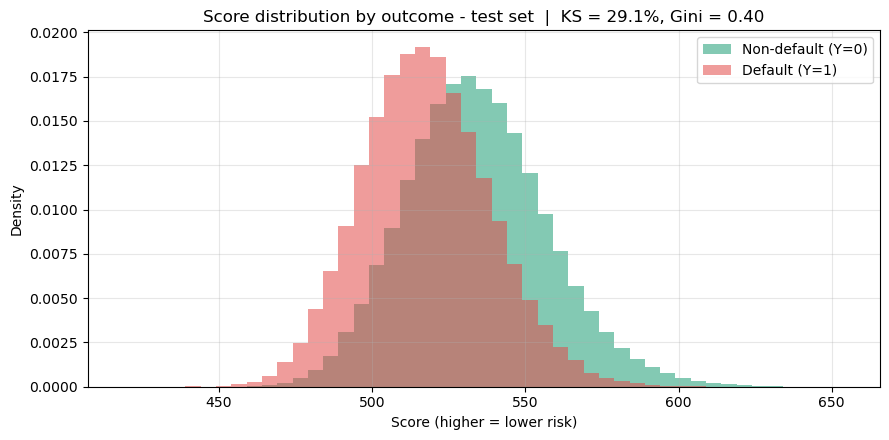

In [8]:
# Score every loan (rounded to whole points, as a scorecard would print it)
score_train = np.round(pd_to_score(pd_cal_train)).astype(int)
score_test  = np.round(pd_to_score(pd_cal_test)).astype(int)

print(pd.Series(score_test).describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())

# A higher score means lower risk, so AUC is measured on -score
auc = roc_auc_score(y_test, -score_test)
fpr, tpr, _ = roc_curve(y_test, -score_test)
ks = (tpr - fpr).max()
print(f"\nScore AUC  : {auc:.4f}   (same as the PD - scaling does not change ranking)")
print(f"Score Gini : {2*auc - 1:.4f}")
print(f"Score KS   : {ks:.2%}   (KS for the champion; pd_model_nn.ipynb only had KS for the challenger)")

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(score_test.min(), score_test.max() + 5, 5)
ax.hist(score_test[y_test.values == 0], bins=bins, alpha=0.55, color='#1D9E75', density=True, label='Non-default (Y=0)')
ax.hist(score_test[y_test.values == 1], bins=bins, alpha=0.55, color='#E24B4A', density=True, label='Default (Y=1)')
ax.set_title(f'Score distribution by outcome - test set  |  KS = {ks:.1%}, Gini = {2*auc-1:.2f}')
ax.set_xlabel('Score (higher = lower risk)'); ax.set_ylabel('Density'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/scorecard_distribution.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Risk grades

The score is cut into bands **20 points wide — one PDO**. With the scaling above, each grade should carry roughly **double the good:bad odds** of the grade below it. The thin tails are merged into the end grades so no grade is too small to be reliable (under 2% of loans). Grade A is the lowest risk.

The grade boundaries are fixed score ranges, so they work for any future population. What we check here is that the actual default rate falls steadily from grade to grade.

In [9]:
# 20-point bands across the main body of the distribution; tails (<1st / >99th percentile) merge into the end bands
lo = int(np.floor(np.percentile(score_train, 1) / PDO) * PDO)
hi = int(np.ceil(np.percentile(score_train, 99) / PDO) * PDO)
inner = list(range(lo, hi + 1, PDO))

# Merge any end band holding less than 2% of the training population into its neighbour
def band_share(edges):
    return pd.Series(pd.cut(score_train, [-np.inf] + edges + [np.inf], right=False)).value_counts(normalize=True, sort=False).values
while len(inner) > 2 and band_share(inner)[0] < 0.02:  inner = inner[1:]
while len(inner) > 2 and band_share(inner)[-1] < 0.02: inner = inner[:-1]

edges = [-np.inf] + inner + [np.inf]
n_grades = len(edges) - 1
grade_labels = [chr(ord('A') + i) for i in range(n_grades)][::-1]   # highest score band = A

def to_grade(scores):
    return pd.cut(scores, edges, right=False, labels=grade_labels)

def band_text(i):
    l, h = edges[i], edges[i + 1]
    if np.isinf(l): return f'< {int(h)}'
    if np.isinf(h): return f'{int(l)}+'
    return f'{int(l)} - {int(h) - 1}'
grade_ranges = {grade_labels[i]: band_text(i) for i in range(n_grades)}

def grade_table(scores, y, pd_cal):
    g = pd.DataFrame({'grade': to_grade(scores), 'y': np.asarray(y), 'pd': pd_cal, 'score': scores})
    t = g.groupby('grade', observed=True).agg(Accounts=('y', 'size'), Defaults=('y', 'sum'),
                                               Bad_rate=('y', 'mean'), Avg_PD=('pd', 'mean'), Avg_score=('score', 'mean'))
    t = t.loc[sorted(t.index, key=lambda s: s)]                     # A first
    t.insert(0, 'Score range', [grade_ranges[i] for i in t.index])
    t.insert(2, 'Pct_of_total', t['Accounts'] / t['Accounts'].sum())
    t['Actual_odds'] = (1 - t['Bad_rate']) / t['Bad_rate']
    t['Odds_vs_next_grade'] = t['Actual_odds'] / t['Actual_odds'].shift(-1)
    return t

grades_test = grade_table(score_test, y_test, pd_cal_test)
fmt = grades_test.copy()
for c in ['Pct_of_total', 'Bad_rate', 'Avg_PD']: fmt[c] = (fmt[c] * 100).round(2).astype(str) + '%'
fmt['Avg_score'] = fmt['Avg_score'].round(0).astype(int)
fmt['Actual_odds'] = fmt['Actual_odds'].round(2).astype(str) + ' : 1'
fmt['Odds_vs_next_grade'] = fmt['Odds_vs_next_grade'].round(2)
print('Risk grades - test set\n')
print(fmt.to_string())
print('\nBad rate rises at every step from grade A down (rank-ordering holds):', grades_test['Bad_rate'].is_monotonic_increasing)

Risk grades - test set

      Score range  Accounts Pct_of_total  Defaults Bad_rate  Avg_PD  Avg_score Actual_odds  Odds_vs_next_grade
grade                                                                                                         
A            580+      6814        2.62%     187.0    2.74%   2.78%        591   35.44 : 1                2.27
B       560 - 579     21159        8.14%    1272.0    6.01%   5.91%        567   15.63 : 1                1.96
C       540 - 559     57943        22.3%    6451.0   11.13%  10.87%        548    7.98 : 1                1.93
D       520 - 539     85621       32.95%   16692.0    19.5%  18.98%        529    4.13 : 1                1.87
E       500 - 519     64317       24.75%   20080.0   31.22%  30.83%        511     2.2 : 1                1.95
F           < 500     23996        9.23%   11260.0   46.92%  47.38%        490    1.13 : 1                 NaN

Bad rate rises at every step from grade A down (rank-ordering holds): True


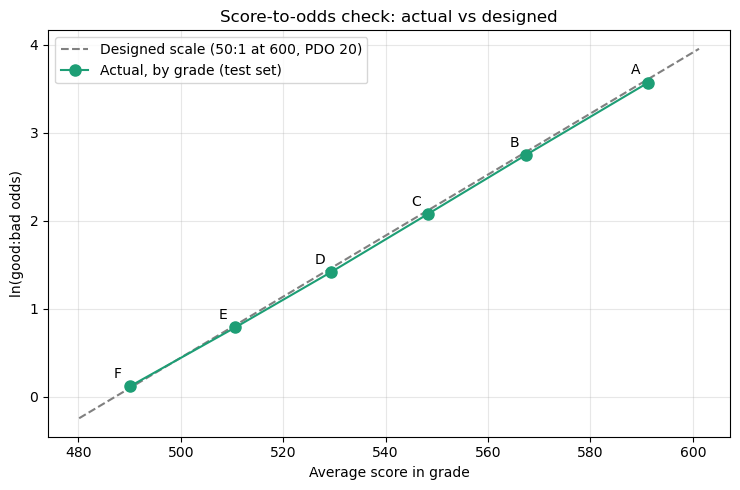

In [10]:
# Does the score scale hold? Actual ln(odds) per grade should sit on the designed line:
# ln(odds) = (Score - Offset) / Factor  — a slope of ln(2) per 20 points
fig, ax = plt.subplots(figsize=(7.5, 5))
xs = np.linspace(grades_test['Avg_score'].min() - 10, grades_test['Avg_score'].max() + 10, 50)
ax.plot(xs, (xs - OFFSET) / FACTOR, ls='--', c='grey', label=f'Designed scale ({BASE_ODDS}:1 at {BASE_SCORE}, PDO {PDO})')
ax.plot(grades_test['Avg_score'], np.log(grades_test['Actual_odds']), 'o-', c='#1D9E75', ms=8, label='Actual, by grade (test set)')
for g, r in grades_test.iterrows():
    ax.annotate(g, (r['Avg_score'], np.log(r['Actual_odds'])), textcoords='offset points', xytext=(-12, 6), fontsize=10)
ax.set_xlabel('Average score in grade'); ax.set_ylabel('ln(good:bad odds)')
ax.set_title('Score-to-odds check: actual vs designed'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/scorecard_odds_check.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Cut-off strategy

Credit policy picks a cut-off by trading **approval rate** against the **bad rate of the approved book**. The gains table below starts from grade A and adds one grade at a time: "if we approve everything down to this grade, what do we get?"

Most lenders run three zones rather than one cut-off: **approve** automatically, **refer** a middle band to an underwriter, and **decline** the rest.

Gains table - approving down to each grade (test set)

      Score range  Accounts  Defaults Bad_rate Cum_approval_rate Bad_rate_of_approved Pct_of_all_defaults_declined
grade                                                                                                             
A            580+      6814     187.0     2.7%              2.6%                 2.7%                        99.7%
B       560 - 579     21159    1272.0     6.0%             10.8%                 5.2%                        97.4%
C       540 - 559     57943    6451.0    11.1%             33.1%                 9.2%                        85.9%
D       520 - 539     85621   16692.0    19.5%             66.0%                14.3%                        56.0%
E       500 - 519     64317   20080.0    31.2%             90.8%                18.9%                        20.1%
F           < 500     23996   11260.0    46.9%            100.0%                21.5%                         0.0%


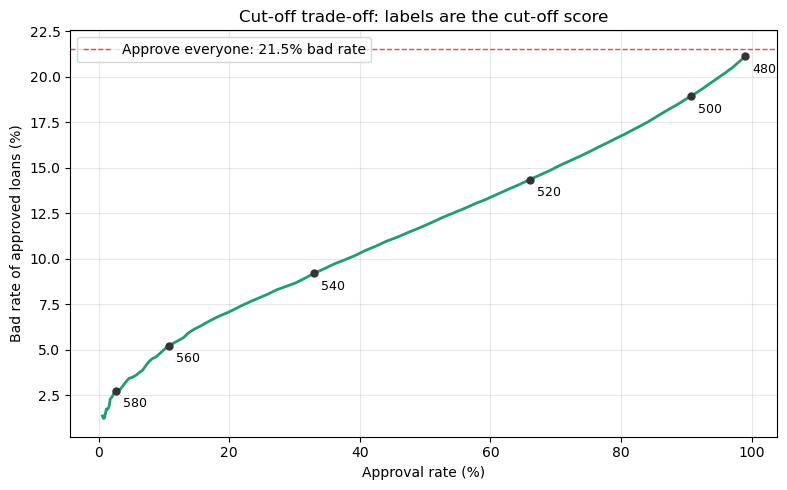

In [11]:
# Gains table, cumulative from the best grade
gains = grades_test[['Score range', 'Accounts', 'Defaults', 'Bad_rate']].copy()
gains['Cum_approval_rate'] = gains['Accounts'].cumsum() / gains['Accounts'].sum()
gains['Bad_rate_of_approved'] = gains['Defaults'].cumsum() / gains['Accounts'].cumsum()
gains['Pct_of_all_defaults_declined'] = 1 - gains['Defaults'].cumsum() / gains['Defaults'].sum()
g = gains.copy()
for c in ['Bad_rate', 'Cum_approval_rate', 'Bad_rate_of_approved', 'Pct_of_all_defaults_declined']:
    g[c] = (g[c] * 100).round(1).astype(str) + '%'
print('Gains table - approving down to each grade (test set)\n')
print(g.to_string())

# Fine-grained trade-off curve: every possible cut-off score
cut_scores = np.arange(np.percentile(score_test, 1), np.percentile(score_test, 99.5), 1)
appr = np.array([(score_test >= c).mean() for c in cut_scores])
bad_appr = np.array([y_test.values[score_test >= c].mean() for c in cut_scores])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(appr * 100, bad_appr * 100, c='#1D9E75', lw=2)
ax.axhline(y_test.mean() * 100, ls='--', c='#E24B4A', lw=1, label=f'Approve everyone: {y_test.mean():.1%} bad rate')
for c in [c for c in range(lo, hi + 1, PDO) if cut_scores.min() <= c <= cut_scores.max()]:
    i = np.argmin(abs(cut_scores - c))
    ax.plot(appr[i] * 100, bad_appr[i] * 100, 'o', c='#333333', ms=5)
    ax.annotate(f'{int(c)}', (appr[i] * 100, bad_appr[i] * 100), textcoords='offset points', xytext=(5, -12), fontsize=9)
ax.set_xlabel('Approval rate (%)'); ax.set_ylabel('Bad rate of approved loans (%)')
ax.set_title('Cut-off trade-off: labels are the cut-off score'); ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/scorecard_cutoff_tradeoff.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
# Illustrative three-zone policy: decline the riskiest ~15%, refer the next ~15%, auto-approve ~70%.
# Cut-offs rounded to the nearest 5 points, as a policy document would state them.
decline_below = int(5 * round(np.percentile(score_train, 15) / 5))
approve_from  = int(5 * round(np.percentile(score_train, 30) / 5))

zone = np.select([score_test >= approve_from, score_test >= decline_below], ['1. Approve', '2. Refer to underwriter'], '3. Decline')
policy = pd.DataFrame({'zone': zone, 'y': y_test.values}).groupby('zone').agg(Accounts=('y', 'size'), Bad_rate=('y', 'mean'))
policy['Pct_of_applicants'] = policy['Accounts'] / policy['Accounts'].sum()
policy['Score rule'] = [f'>= {approve_from}', f'{decline_below} - {approve_from - 1}', f'< {decline_below}']
policy = policy[['Score rule', 'Accounts', 'Pct_of_applicants', 'Bad_rate']]
p = policy.copy()
for c in ['Pct_of_applicants', 'Bad_rate']: p[c] = (p[c] * 100).round(1).astype(str) + '%'
print(f'Illustrative policy - test set (overall bad rate {y_test.mean():.1%})\n')
print(p.to_string())

Illustrative policy - test set (overall bad rate 21.5%)

                        Score rule  Accounts Pct_of_applicants Bad_rate
zone                                                                   
1. Approve                  >= 515    191599             73.7%    15.6%
2. Refer to underwriter  505 - 514     32460             12.5%    31.8%
3. Decline                   < 505     35791             13.8%    43.8%


## 5. Points breakdown and reason codes

This is where a scorecard on an ML model differs from a traditional one — and where SHAP earns its place.

- The score is a straight line in log-odds: `Score = Offset − Factor × logit(PD)`.
- XGBoost's SHAP values are **also in log-odds**: `margin = base value + Σ SHAP`.

Put the two together:

$$\text{Score} = \underbrace{\text{Offset} - \text{Factor} \times (\text{base value} - \ln 3)}_{\text{base points}} \; + \; \sum_{\text{features}} \underbrace{(-\text{Factor} \times \text{SHAP}_i)}_{\text{points for feature } i}$$

So every applicant gets **base points + points per characteristic that add up exactly to their score** — the same structure as a traditional points table. The characteristics that cost the most points are the applicant's **reason codes**: what an adverse-action letter or an underwriter's screen shows.

The difference from a traditional scorecard: points here are personal. Two applicants with the same FICO can get different FICO points, because the trees capture interactions (FICO matters more when DTI is high). Section 5b averages them back into a familiar attribute table.

In [13]:
# Exact TreeSHAP contributions from XGBoost itself (same values as shap.TreeExplainer, much faster).
# Last column is the base value (bias).
# Run on a 50,000-loan sample of the test set: exact SHAP on all 260k loans takes over 10 minutes.
# iteration_range matches the trees predict() uses (up to the early-stopping best iteration).
sample_idx = x_test.sample(50_000, random_state=42).index
contribs = xgb_model.get_booster().predict(xgb.DMatrix(x_test.loc[sample_idx]), pred_contribs=True,
                                           iteration_range=(0, xgb_model.best_iteration + 1))
shap_vals, base_value = contribs[:, :-1].astype(float), float(contribs[0, -1])

BASE_POINTS = OFFSET - FACTOR * (base_value - np.log(CLASS_WEIGHT))
points = pd.DataFrame(-FACTOR * shap_vals, columns=x_test.columns, index=sample_idx)

# Check: base points + feature points reproduce the score (before rounding)
pos     = x_test.index.get_indexer(sample_idx)
rebuilt = BASE_POINTS + points.sum(axis=1).values
exact   = pd_to_score(pd_cal_test[pos].astype(float))
print(f"Base points (every applicant starts here): {BASE_POINTS:.1f}")
print(f"Largest gap between rebuilt score and actual score: {np.abs(rebuilt - exact).max():.6f} points")

Base points (every applicant starts here): 524.3
Largest gap between rebuilt score and actual score: 0.000235 points


In [14]:
# Plain-English names for the characteristics (what a reason code would say)
reason_text = {
    'fico_avg': 'FICO score', 'tot_dti': 'Debt-to-income ratio', 'loan_amnt': 'Loan amount requested',
    'inq_last_12m': 'Credit enquiries, last 12 months', 'inq_last_12m_missing': 'Enquiry history not available',
    'num_acc_op_past_24mths': 'Accounts opened, last 24 months', 'num_acc_op_past_12m': 'Accounts opened, last 12 months',
    'tot_unsec_util': 'Unsecured utilisation %', 'tot_unsec_limit': 'Unsecured credit limit',
    'tot_unsec_bal': 'Unsecured balance', 'tot_limit': 'Total credit limit', 'tot_sec_limit': 'Secured credit limit',
    'total_inc': 'Annual income', 'tot_acct': 'Total accounts', 'tot_unsec_acct': 'Unsecured accounts',
    'tot_sec_acct': 'Mortgage accounts', 'emp_length_num': 'Years in employment',
    'emp_length_missing': 'Employment length not provided', 'Num_30DPD_2yrs': '30+ DPD events, last 2 years',
    'Num_90DPD_2yrs': '90+ DPD accounts, last 2 years', 'num_accts_ever_120_pd': 'Accounts ever 120+ DPD',
    'collections_12_mths_ex_med': 'Collections, last 12 months', 'tot_chargeoff_within_12_mths': 'Charge-offs, last 12 months',
    'zip_code': 'Postcode area', 'home_ownership_RENT': 'Home ownership: renting',
    'home_ownership_MORTGAGE': 'Home ownership: mortgage', 'purpose_credit_card': 'Purpose: credit card refinance',
    'purpose_debt_consolidation': 'Purpose: debt consolidation', 'purpose_educational': 'Purpose: education',
    'verification_status_Verified': 'Income verified', 'verification_status_Source Verified': 'Income source verified',
}

# Applicant values in original units: numeric fields from x_test_raw, 0/1 flags from x_test
raw_view = x_test.loc[sample_idx].copy().astype(object)
for c in x_test.columns:
    if c in x_test_raw.columns: raw_view[c] = x_test_raw.loc[sample_idx, c]
FLAG_COLS = [c for c in x_test.columns if c.endswith('_missing') or c.startswith(('home_ownership_', 'purpose_', 'verification_status_'))]

def show_value(c, v):
    if c in FLAG_COLS: return 'Yes' if float(v) == 1 else 'No'
    if c == 'zip_code': return f'{float(v):.2%} of loans'
    if c == 'fico_avg': return f'{float(v):.0f}'
    if c in ('loan_amnt', 'total_inc', 'tot_limit', 'tot_unsec_limit', 'tot_sec_limit', 'tot_unsec_bal'): return f'${float(v):,.0f}'
    if c in ('tot_dti', 'tot_unsec_util'): return f'{float(v):.1f}%'
    if pd.api.types.is_number(v) and float(v).is_integer(): return f'{int(v)}'
    return f'{float(v):.1f}'

def applicant_card(idx, top_n=8, n_reasons=3):
    i = x_test.index.get_loc(idx)
    p = points.loc[idx]
    s = int(score_test[i])
    print('=' * 72)
    print(f"Applicant {idx}   Score {s}   Grade {to_grade(np.array([s]))[0]}   "
          f"PD {pd_cal_test[i]:.1%}   Actual outcome: {'DEFAULT' if y_test.iloc[i] == 1 else 'paid'}")
    print('-' * 72)
    order = p.abs().sort_values(ascending=False).index[:top_n]
    rows = [('Base points', '', BASE_POINTS)] + [(reason_text.get(c, c), show_value(c, raw_view.loc[idx, c]), p[c]) for c in order]
    rows.append((f'All other {len(p) - top_n} characteristics', '', p.drop(order).sum()))
    for name, val, pts in rows:
        print(f"  {name:<38}{val:>16}{pts:>+10.1f}")
    print(f"  {'':<38}{'Score':>16}{BASE_POINTS + p.sum():>10.1f}")
    reasons = p.sort_values().index[:n_reasons]
    reasons = [r for r in reasons if p[r] < 0]
    print('\n  Top reason codes (characteristics that cost the most points):')
    for k, r in enumerate(reasons, 1):
        print(f"    {k}. {reason_text.get(r, r)} ({show_value(r, raw_view.loc[idx, r])}): {p[r]:+.1f} points")

# One low-risk, one middle and one high-risk applicant from the test set
rng = np.random.default_rng(7)
for q in (0.95, 0.50, 0.05):
    target = np.percentile(score_test, q * 100)
    candidates = sample_idx[np.abs(score_test[pos] - target) <= 1]
    applicant_card(rng.choice(candidates))

Applicant 47323   Score 571   Grade B   PD 5.3%   Actual outcome: paid
------------------------------------------------------------------------
  Base points                                               +524.3
  Loan amount requested                           $3,000     +18.3
  Debt-to-income ratio                              8.3%      +9.6
  Purpose: credit card refinance                     Yes      +6.6
  30+ DPD events, last 2 years                         2      -5.4
  Mortgage accounts                                    5      +3.5
  Enquiry history not available                      Yes      +3.2
  Unsecured balance                              $14,740      +3.1
  Unsecured credit limit                         $83,905      +2.6
  All other 22 characteristics                                +4.6
                                                   Score     570.6

  Top reason codes (characteristics that cost the most points):
    1. 30+ DPD events, last 2 years (2): -5.4 points
 

### 5b. The familiar view: average points by attribute

Averaging each applicant's points within value bands gives a table shaped like a traditional scorecard (characteristic → attribute → points). It is a summary of the model, not the model itself: an individual's points can differ from the band average because of interactions with their other characteristics.

In [15]:
def attribute_table(feature, n_bins=5):
    vals = pd.to_numeric(raw_view[feature])
    is_flag = vals.nunique() <= 2
    bins = vals if is_flag else pd.qcut(vals, n_bins, duplicates='drop')
    t = pd.DataFrame({'bin': bins, 'pts': points[feature], 'y': y_test.loc[sample_idx].values}).groupby('bin', observed=True).agg(
        Accounts=('y', 'size'), Bad_rate=('y', 'mean'), Avg_points=('pts', 'mean'))
    if is_flag:
        t.index = ['Yes' if int(v) == 1 else 'No' for v in t.index]
    else:
        ivs, n = list(t.index), len(t)
        t.index = [f'up to {show_value(feature, iv.right)}' if k == 0 else
                   f'over {show_value(feature, iv.left)}' if k == n - 1 else
                   f'{show_value(feature, iv.left)} to {show_value(feature, iv.right)}' for k, iv in enumerate(ivs)]
    t.insert(0, 'Characteristic', reason_text.get(feature, feature))
    t['Bad_rate'] = (t['Bad_rate'] * 100).round(1).astype(str) + '%'
    t['Avg_points'] = t['Avg_points'].round(1)
    return t

# The six characteristics that move the score the most (mean absolute points)
top_features = points.abs().mean().sort_values(ascending=False).head(6)
print('Characteristics ranked by average points impact:\n')
print(top_features.rename(index=reason_text).round(1).to_string(), '\n')

scorecard_view = pd.concat([attribute_table(f) for f in top_features.index])
scorecard_view.index.name = 'Attribute'
print(scorecard_view.to_string())

Characteristics ranked by average points impact:

Loan amount requested              9.8
Debt-to-income ratio               7.0
FICO score                         5.6
Enquiry history not available      5.1
Accounts opened, last 24 months    5.0
Unsecured credit limit             4.8 

                                      Characteristic  Accounts Bad_rate  Avg_points
Attribute                                                                          
up to $7,000                   Loan amount requested     10889    16.9%        16.6
$7,000 to $10,000              Loan amount requested      9395    19.1%         8.4
$10,000 to $15,000             Loan amount requested     10626    21.3%         0.0
$15,000 to $21,575             Loan amount requested      9091    24.0%        -6.5
over $21,575                   Loan amount requested      9999    24.8%       -15.2
up to 10.6%                     Debt-to-income ratio     10016    16.1%        11.3
10.6% to 15.4%                  Debt-to-in

## 6. Summary

### The scorecard specification

| Item | Value |
|---|---|
| Underlying model | XGBoost champion from `pd_model_nn.ipynb` (30 application-time characteristics) |
| Calibration | Prior correction for the 1:3 class weight: logit(PD) − ln 3. Mean PD 21.3% vs actual 21.5% (test set) |
| Scaling | 600 points = 50:1 good:bad odds, PDO 20 → **Score = 487.12 + 28.85 × ln(odds)** |
| Score range | 480 – 592 covers 98% of loans (1st – 99th percentile); median 529 |
| Discrimination | AUC 0.70, Gini 0.40, KS 29.1% (test set) |
| Risk grades | 6 grades, A (580+) to F (< 500), each 20 points = one PDO. Bad rate 2.7% in A up to 47.2% in F, always rising |
| Scale check | Actual odds go up 1.9× – 2.3× per grade, against a designed 2× |
| Illustrative policy | Approve ≥ 515 (74% of applicants, 15.6% bad rate) · Refer 505 – 514 (12%) · Decline < 505 (14%, 43.9% bad rate) |

### What the scorecard build shows about the model

1. **Calibration is not optional.** The raw PD averaged ~43% against a real default rate of 21.5%, because of the 1:3 class weight. Scoring the raw PD would put every applicant **32 points too low** (ln 3 × Factor). Cut-offs, pricing and expected loss would all be wrong, even though the ranking (AUC) looks fine.
2. **Grade D is too concentrated.** It holds 33% of loans. A production scorecard would usually split the middle into 10-point (half-PDO) bands, so policy has finer steps where most applicants sit.
3. **"Enquiry history not available" behaves like a vintage proxy.** The enquiry field is missing mostly for older loans, which had lower default rates (18.9% when missing vs 25.1% when present). The model gives these borrowers points for *when* they applied, not for *who* they are. It should be reviewed before the model is used for decisions, and it is not a valid reason code. The same check applies to "Employment length not provided".
4. **Postcode is a fair-lending risk.** `zip_code` is a model input. Postcode can act as a proxy for protected characteristics, and US rules (ECOA / Reg B) expect adverse-action reasons to be specific and lawful. In production it would be removed, or justified and kept out of reason codes.

### Next steps for production

- **Calibrate to a long-run default rate**, not only the development sample, and recheck it on out-of-time data once matured vintages are available.
- **Monitor the score, not only the model:** score PSI, characteristic stability (CSI) for the main drivers, and bad rate by grade against expectation.
- **Track overrides and referrals:** approvals below the cut-off and declines above it, with their performance.
- **Keep the scale fixed across rebuilds.** A new model should be re-scaled to the same 600 @ 50:1, PDO 20, so a 540 means the same risk to policy, pricing and collections.